# 07 — Comparación final de SAT-solvers

Este notebook junta los resultados de los 5 solvers (SATtabla, Tableaux, DPLL,
WalkSAT, MiniSAT) en una tabla comparativa, y genera `resultados/modelos_TODOS.json`
y `resultados/resultados_TODOS.csv` para el informe.

- Lee los `modelos_*.json` y `resultados_*.csv` de `resultados/`.
- Arma la tabla por regla y la tabla pivote (solo "Reglas 1 a 5").
- Dibuja un gráfico de barras (escala log) con los tiempos de "Reglas 1 a 5".
- Incluye un resumen de **qué parametrizamos en cada solver**.

## Parámetros del proyecto

Antes de comparar, conviene recordar **qué parametrizamos** en cada solver
(útil para la sustentación):

| Solver | Parámetros | Cuáles | ¿Afectan el resultado? |
|---|---|---|---|
| **SATtabla** | 0 | — | No (fuerza bruta) |
| **Tableaux** | 3 | Recorrido (anchura/profundidad/backtracking), `MAX_SEG`, `max_seg` por llamada | Sí (anchura explota, profundidad y backtracking son más rápidos) |
| **DPLL** | 1 | Heurística de elección del literal (aleatoria) | Solo el tiempo (el modelo siempre es válido) |
| **WalkSAT** | 4 | `max_flips`, `max_tries`, `p` (ruido), `semilla` | Sí (modelo vs. `sin modelo`) |
| **MiniSAT** | 1 | Forzar reglas 1, 2 y 3 (solo 5 juntas) | Sí (modelo trivial de Tseitin vs. ciclo real) |

**Decisiones de ingeniería:**
- `MAX_SEG` en Tableaux: 30 s para reglas sueltas, 3600 s para las 5 juntas.
- WalkSAT usa la **versión incremental** (guarda `ntrue` y `occ`): 385 277 volteos en 1 s.
- MiniSAT añade **110 cláusulas** (reglas 1, 2 y 3) solo para las 5 juntas: 858 → 968.

In [1]:
import json, os, glob
import pandas as pd

# 1) Juntar todos los modelos_*.json en modelos_TODOS.json
os.makedirs('resultados', exist_ok=True)

modelos = {}
for path in sorted(glob.glob('resultados/modelos_*.json')):
    if os.path.basename(path) == 'modelos_TODOS.json':
        continue
    with open(path, 'r', encoding='utf-8') as f:
        datos = json.load(f)
    modelos.update(datos)
    print('Cargado', path)

with open('resultados/modelos_TODOS.json', 'w', encoding='utf-8') as f:
    json.dump(modelos, f, ensure_ascii=False, indent=2)

print('\nSolvers en modelos_TODOS.json:', list(modelos.keys()))

Cargado resultados/modelos_DPLL.json
Cargado resultados/modelos_MiniSAT.json
Cargado resultados/modelos_SATtabla.json
Cargado resultados/modelos_Tableaux.json
Cargado resultados/modelos_WalkSAT.json

Solvers en modelos_TODOS.json: ['DPLL', 'MiniSAT', 'SATtabla', 'Tableaux', 'WalkSAT']


In [7]:
# Tabla compacta: solo "Reglas 1 a 5", pero con columnas clave
tabla_compacta = tabla_final[tabla_final['Regla'] == 'Reglas 1 a 5'].copy()
tabla_compacta = tabla_compacta[['Solver', 'Resultado', 'Tiempo (s)', '¿Tiene modelo?']]
tabla_compacta = tabla_compacta.sort_values('Tiempo (s)', na_position='last')
tabla_compacta.reset_index(drop=True, inplace=True)
tabla_compacta

,Solver,Resultado,Tiempo (s),¿Tiene modelo?
0,MiniSAT,Satisfacible,0.0014,True
1,DPLL,modelo,0.0183,True
2,WalkSAT,modelo,1.2184,True
3,Tableaux profundidad,tiempo agotado,30.0010,False
4,Tableaux backtracking,tiempo agotado,30.0110,False
5,Tableaux anchura,tiempo agotado,30.1330,False
6,SATtabla,modelo,79.9270,True


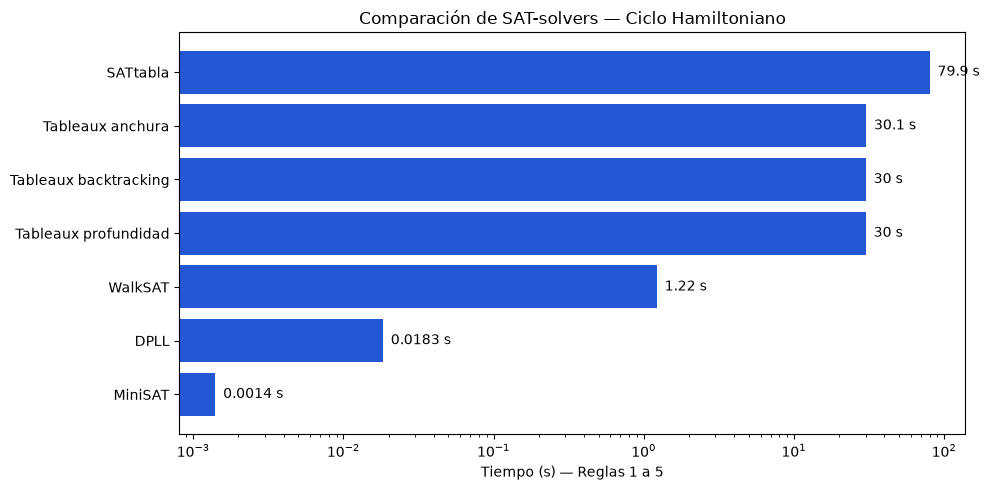

In [9]:
import matplotlib.pyplot as plt

pivote_plot = tabla_pivote.dropna(subset=['Tiempo (s)']).copy()
pivote_plot['Tiempo (s)'] = pivote_plot['Tiempo (s)'].astype(float)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(pivote_plot['Solver'], pivote_plot['Tiempo (s)'], color='#2457d6')
ax.set_xlabel('Tiempo (s) — Reglas 1 a 5')
ax.set_title('Comparación de SAT-solvers — Ciclo Hamiltoniano')
ax.set_xscale('log')
for i, (t, s) in enumerate(zip(pivote_plot['Tiempo (s)'], pivote_plot['Solver'])):
    ax.text(t, i, f'  {t:.3g} s', va='center')
plt.tight_layout()
plt.show()

In [10]:
# Ciclos encontrados por cada solver en "Reglas 1 a 5"
from logica import Descriptor
from problema import CicloHamiltoniano

# Reconstruimos H para usar el descriptor Visita(c,t)
ciudades = ['Baq', 'Buc', 'Bog', 'Med', 'Per']
aristas  = [{0,1}, {1,2}, {2,3}, {3,4}, {2,4}, {0,2}, {1,4}]
coords   = {0:(0,3), 1:(3,3), 2:(1.5,1.8), 3:(0.3,0), 4:(2.7,0)}
H = CicloHamiltoniano(ciudades, aristas, coords)

letras_originales = set(H.Visita.ravel([c, t])
                        for c in range(H.n) for t in range(H.n))

def ciclo_de(modelo):
    '''Devuelve el recorrido como lista de ciudades, o None si el modelo no es un ciclo.'''
    if modelo is None:
        return None
    I_filtrado = {k: modelo.get(k, False) for k in letras_originales}
    orden = H._orden(I_filtrado)
    if None in orden:
        return None
    return [H.ciudades[c] for c in orden]

print(f"{'Solver':<24s} | {'Ciclo encontrado':<45s} | {'Tiempo (s)':>10s}")
print('-' * 85)

for _, fila in tabla_pivote.iterrows():
    solver = fila['Solver']
    # Extraer el modelo del solver
    if solver.startswith('Tableaux'):
        modelo = modelos['Tableaux']['Reglas 1 a 5'][solver]['modelo']
    else:
        modelo = modelos[solver]['Reglas 1 a 5']['modelo']

    ciclo = ciclo_de(modelo)
    if ciclo is None:
        texto = '(sin modelo / tiempo agotado)'
    else:
        texto = ' -> '.join(ciclo) + ' -> ' + ciclo[0]

    print(f'{solver:<24s} | {texto:<45s} | {fila["Tiempo (s)"]:>10.4f}')

Solver                   | Ciclo encontrado                              | Tiempo (s)
-------------------------------------------------------------------------------------
MiniSAT                  | Per -> Med -> Bog -> Baq -> Buc -> Per        |     0.0014
DPLL                     | Per -> Med -> Bog -> Baq -> Buc -> Per        |     0.0183
WalkSAT                  | Buc -> Baq -> Bog -> Med -> Per -> Buc        |     1.2184
Tableaux profundidad     | (sin modelo / tiempo agotado)                 |    30.0010
Tableaux backtracking    | (sin modelo / tiempo agotado)                 |    30.0110
Tableaux anchura         | (sin modelo / tiempo agotado)                 |    30.1330
SATtabla                 | Per -> Buc -> Baq -> Bog -> Med -> Per        |    79.9270


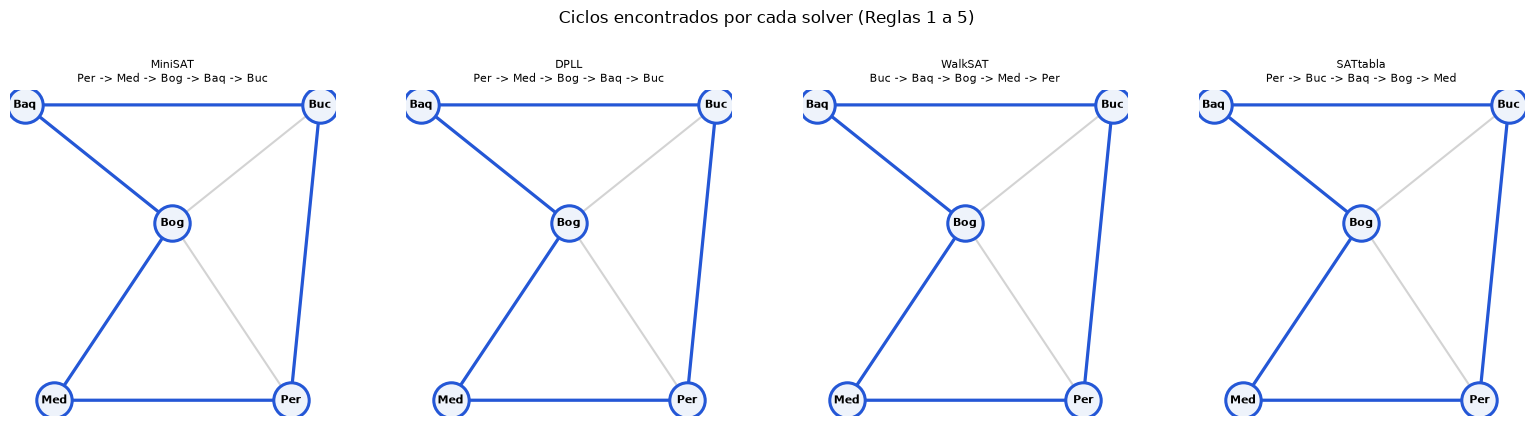

In [11]:
import matplotlib.pyplot as plt

# Solo dibujamos los solvers que encontraron modelo
solvers_con_modelo = ['MiniSAT', 'DPLL', 'WalkSAT', 'SATtabla']

fig, axes = plt.subplots(1, len(solvers_con_modelo), figsize=(4 * len(solvers_con_modelo), 4))
if len(solvers_con_modelo) == 1:
    axes = [axes]

for ax, solver in zip(axes, solvers_con_modelo):
    if solver.startswith('Tableaux'):
        modelo = modelos['Tableaux']['Reglas 1 a 5'][solver]['modelo']
    else:
        modelo = modelos[solver]['Reglas 1 a 5']['modelo']

    I_filtrado = {k: modelo.get(k, False) for k in letras_originales}
    orden = H._orden(I_filtrado)

    # Dibujar el grafo
    P = H._xy()
    for a in H.E:
        u, v = tuple(a)
        ax.plot([P[u][0], P[v][0]], [P[u][1], P[v][1]], color='lightgray', lw=1.5, zorder=1)

    # Dibujar el ciclo
    for t in range(H.n):
        u = orden[t]
        v = orden[(t + 1) % H.n]
        ax.annotate('', xy=P[v], xytext=P[u],
                    arrowprops=dict(arrowstyle='-|>', color='#2457d6', lw=2.3), zorder=2)

    # Nodos
    for i in range(H.n):
        ax.scatter(*P[i], s=650, color='#eef3fb', edgecolors='#2457d6', lw=2.2, zorder=3)
        ax.text(P[i][0], P[i][1], H.ciudades[i], ha='center', va='center',
                fontsize=8, fontweight='bold', zorder=4)

    ciclo = ' -> '.join(H.ciudades[c] for c in orden)
    ax.set_title(f'{solver}\n{ciclo}', fontsize=8)
    ax.set_aspect('equal')
    ax.axis('off')

fig.suptitle('Ciclos encontrados por cada solver (Reglas 1 a 5)', fontsize=12, y=1.05)
plt.tight_layout()
plt.show()

## Conclusiones

### Resultados (Reglas 1 a 5)

| Solver | Resultado | Tiempo | Modelo |
|---|---|---|---|
| **MiniSAT** | Satisfacible | **0.0014 s** | ✅ |
| **DPLL** | modelo | **0.0183 s** | ✅ |
| **WalkSAT** | modelo | **1.2184 s** | ✅ |
| SATtabla | modelo | 79.927 s | ✅ |
| Tableaux anchura | tiempo agotado | 30.133 s | ❌ |
| Tableaux profundidad | tiempo agotado | 30.001 s | ❌ |
| Tableaux backtracking | tiempo agotado | 30.011 s | ❌ |

> **Nota:** el tiempo de Tableaux anchura en esta corrida fue 30.133 s
> (se cortó a los 30 s). En una corrida anterior se dejó 3858 s y **tampoco
> terminó**, así que con 30 s ya agota y no vale la pena esperar más.

### Hallazgos

1. **La representación no es el cuello de botella.** MiniSAT, DPLL y WalkSAT
   usan **la misma forma clausal de Tseitin** (858 cláusulas, 319 letras). La
   diferencia es el **algoritmo**:
   - MiniSAT: propagación unitaria + análisis de conflictos + aprendizaje.
   - DPLL: propagación unitaria + branching.
   - WalkSAT: búsqueda local incremental.
   - SATtabla: enumeración exhaustiva.
   - Tableaux: árbol de ramificación (explota).

2. **Tableaux no escala.** Ninguno de los 3 recorridos encuentra modelo de las
   5 juntas: los 3 agotan el tiempo a los 30 s (y en una corrida anterior,
   anchura llegó a 3858 s sin terminar).

3. **Completitud vs. velocidad.**
   - MiniSAT y DPLL son **completos** y **rápidos**.
   - WalkSAT es **incompleto** pero **rápido**.
   - SATtabla es **completo** pero **lento**.
   - Tableaux es **completo** pero **no escala**.

4. **MiniSAT vs. DPLL.** MiniSAT es ~13× más rápido que DPLL (0.0014 s vs.
   0.0183 s). La diferencia es la **implementación**: DPLL es el algoritmo
   conceptual; MiniSAT añade décadas de optimizaciones.

5. **MiniSAT forzó reglas 1, 2 y 3.** Sin las reglas forzadas, `pycosat`
   devolvía un modelo trivial de Tseitin. Con las reglas forzadas, el modelo
   **sí** es un ciclo hamiltoniano (`Per -> Med -> Bog -> Baq -> Buc -> Per`).
   Eso añadió **110 cláusulas** (858 → 968).

### Lo que se entrega

- `resultados/modelos_TODOS.json`: los modelos de los 5 solvers.
- `resultados/resultados_TODOS.csv`: la tabla comparativa plana.
- Los CSV y JSON individuales de cada solver en `resultados/`.
- Los notebooks de cada solver, con su explicación y visualización.